## Colab GPU와 프로젝트 파일 확인

In [19]:
from pathlib import Path
import os
import torch

candidates = [Path.cwd(), Path("/content/YacssoK")]
repo = next(
    (p.resolve() for p in candidates if (p / "configs").is_dir() and (p / "src").is_dir()),
    None,
)

if repo is None:
    raise FileNotFoundError("Colab에서 YacssoK 프로젝트 폴더를 찾지 못했어요.")

os.chdir(repo)

print("프로젝트 위치:", Path.cwd())
print("CUDA 사용 가능:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

files = [
    "data/class_map.json",
    "data/annotations/v1.json",
    "data/splits/v0/train.txt",
    "data/splits/v0/val.txt",
    "data/splits/v1/train.txt",
    "data/splits/v1/val.txt",
    "outputs/1028_dataB_yolov8s_v1_clean/best.pt",
]

for name in files:
    print(f"{'있음' if Path(name).is_file() else '없음'}: {name}")

프로젝트 위치: /content/YacssoK
CUDA 사용 가능: True
GPU: NVIDIA A100-SXM4-40GB
있음: data/class_map.json
없음: data/annotations/v1.json
없음: data/splits/v0/train.txt
없음: data/splits/v0/val.txt
없음: data/splits/v1/train.txt
없음: data/splits/v1/val.txt
있음: outputs/1028_dataB_yolov8s_v1_clean/best.pt


## Colab에 업로드된 데이터 위치 확인

In [20]:
from pathlib import Path
import shutil

repo = Path("/content/YacssoK")
names = ["train_images", "train_annotations"]
sources = {name: Path("/content") / name for name in names}
missing = [str(path) for path in sources.values() if not path.is_dir()]

if missing:
    raise FileNotFoundError("아직 못 찾은 폴더:\n" + "\n".join(missing))

for name, source in sources.items():
    destination = repo / "data" / "raw" / name
    shutil.copytree(source, destination, dirs_exist_ok=True)
    count = sum(1 for p in destination.rglob("*") if p.is_file())
    print(f"{name}: {count}개 파일 → {destination}")

train_images: 232개 파일 → /content/YacssoK/data/raw/train_images
train_annotations: 765개 파일 → /content/YacssoK/data/raw/train_annotations


### Colab 파일 저장 확인

In [22]:
%cd /content/YacssoK
!uv run --locked python scripts/prepare_data.py --config configs/base.yaml

/content
이미지 232장, 박스 763개, 클래스 56개
이미지당 알약 수 분포: {2: 7, 3: 151, 4: 74}
저장: data/class_map.json, /content/YacssoK/data/processed/records.json


## 팀에 저장된 v1 분할 목록 가져오기

In [30]:
from pathlib import Path
import subprocess

repo = Path("/content/YacssoK")

subprocess.run(["git", "fetch", "origin", "choongeun"], cwd=repo, check=True)

for name in ["data/splits/v1/train.txt", "data/splits/v1/val.txt"]:
    content = subprocess.check_output(
        ["git", "show", f"FETCH_HEAD:{name}"],
        cwd=repo,
    )
    path = repo / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    print(f"{name}: {len(content.decode('utf-8').splitlines())}장")

data/splits/v1/train.txt: 185장
data/splits/v1/val.txt: 47장


In [31]:
%cd /content/YacssoK
!uv run --locked python scripts/clean_labels.py --config configs/base.yaml --version v1

from pathlib import Path

print("v1 라벨 생성:", Path("data/annotations/v1.json").is_file())
print("분할 유지:", len(Path("data/splits/v1/train.txt").read_text().splitlines()), "train /",
      len(Path("data/splits/v1/val.txt").read_text().splitlines()), "validation")

/content
원본 232장 → 정제 232장, 수정 내역: {'clip': 1, 'drop_tiny': 1}
저장: /content/YacssoK/data/annotations/v1.json, v1_report.csv, splits/v1/
v1 라벨 생성: True
분할 유지: 185 train / 47 validation


## 비교에 필요한 파일 점검

In [32]:
from pathlib import Path

checks = {
    "YOLO 체크포인트": "outputs/1028_dataB_yolov8s_v1_clean/best.pt",
    "YOLO 설정": "outputs/1028_dataB_yolov8s_v1_clean/config.yaml",
    "클래스 목록": "data/class_map.json",
    "v1 라벨": "data/annotations/v1.json",
    "v1 학습 분할": "data/splits/v1/train.txt",
    "v1 검증 분할": "data/splits/v1/val.txt",
    "RCNN 설정": "configs/rcnn_baseline.yaml",
}

for label, name in checks.items():
    path = Path(name)
    print(f"{'있음' if path.is_file() else '없음'}: {label} — {name}")

있음: YOLO 체크포인트 — outputs/1028_dataB_yolov8s_v1_clean/best.pt
있음: YOLO 설정 — outputs/1028_dataB_yolov8s_v1_clean/config.yaml
있음: 클래스 목록 — data/class_map.json
있음: v1 라벨 — data/annotations/v1.json
있음: v1 학습 분할 — data/splits/v1/train.txt
있음: v1 검증 분할 — data/splits/v1/val.txt
있음: RCNN 설정 — configs/rcnn_baseline.yaml


## RCNN 학습

In [33]:
import pandas as pd

from src.interfaces import OUTPUT_DIR
from src.train import run
from src.utils import get_device, load_config

YOLO_EXP = "1028_dataB_yolov8s_v1_clean"
RCNN_EXP = "1026_modelB_frcnn_v1_compare"

rcnn_checkpoint = OUTPUT_DIR / RCNN_EXP / "best.pt"

if rcnn_checkpoint.exists():
    print("RCNN 체크포인트가 이미 있어 학습을 건너뜁니다:", rcnn_checkpoint)
else:
    yolo_cfg = load_config(OUTPUT_DIR / YOLO_EXP / "config.yaml")
    rcnn_cfg = load_config("configs/rcnn_baseline.yaml")

    rcnn_cfg["exp_name"] = RCNN_EXP
    rcnn_cfg["owner"] = "modelB"
    rcnn_cfg["note"] = "YOLO와 같은 v1 분할에서 mAP 비교"
    rcnn_cfg["data"] = dict(yolo_cfg["data"])
    rcnn_cfg["eval"] = dict(yolo_cfg["eval"])
    rcnn_cfg["augment"] = dict(yolo_cfg.get("augment") or {})
    rcnn_cfg["train"]["device"] = "auto"

    print("학습 장치:", get_device("auto"))
    print("학습 이미지 185장 / 검증 이미지 47장")
    rcnn_result = run(rcnn_cfg)
    display(pd.DataFrame([rcnn_result]))

학습 장치: cuda:0
학습 이미지 185장 / 검증 이미지 47장


epoch 1/20:   0%|          | 0/47 [00:00<?, ?it/s]/content/YacssoK/src/models/rcnn.py:100: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  total += float(loss)


[rcnn] epoch 1: train_loss=1.2591


[rcnn] epoch 2: train_loss=0.8368


[rcnn] epoch 3: train_loss=0.6230


...

[rcnn] epoch 17: train_loss=0.0667


[rcnn] epoch 18: train_loss=0.0617


[rcnn] epoch 19: train_loss=0.0597


[rcnn] epoch 20: train_loss=0.0605

[1026_modelB_frcnn_v1_compare] 검증 mAP@[0.75:0.95]=0.73839  mAP75=0.83801  (3.38분)
결과 저장: /content/YacssoK/outputs/1026_modelB_frcnn_v1_compare


,exp_name,owner,model,data_version,augment,epochs,img_size,train_min,finished_at,note,map,map_75,map_large,mar_1,mar_10,mar_100,mar_large
0,1026_modelB_frcnn_v1_compare,modelB,rcnn:fasterrcnn_resnet50_fpn_v2,v1,none,20,640,3.38,2026-10-26 06:32,YOLO와 같은 v1 분할에서 mAP 비교,0.73839,0.83801,0.73839,0.75267,0.75267,0.75267,0.75267


## YOLOv8 학습

In [34]:
%cd /content/YacssoK
!uv run --locked python scripts/export_yolo.py --config configs/yolo_v1_clean.yaml

/content
train: 185장
val: 47장
저장: /content/YacssoK/data/yolo/v1/data.yaml


In [36]:
# 새 체크포인트 지점 만들기
%cd /content/YacssoK
!uv run --locked python scripts/run_train.py \
  --config configs/yolo_v1_clean.yaml \
  --epochs 20 \
  --exp-name 1026_dataB_yolov8s_v1_compare20

/content
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.11.17 torch-2.6.0+cu124 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/YacssoK/data/yolo/v1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, drop

## 비교 그래프

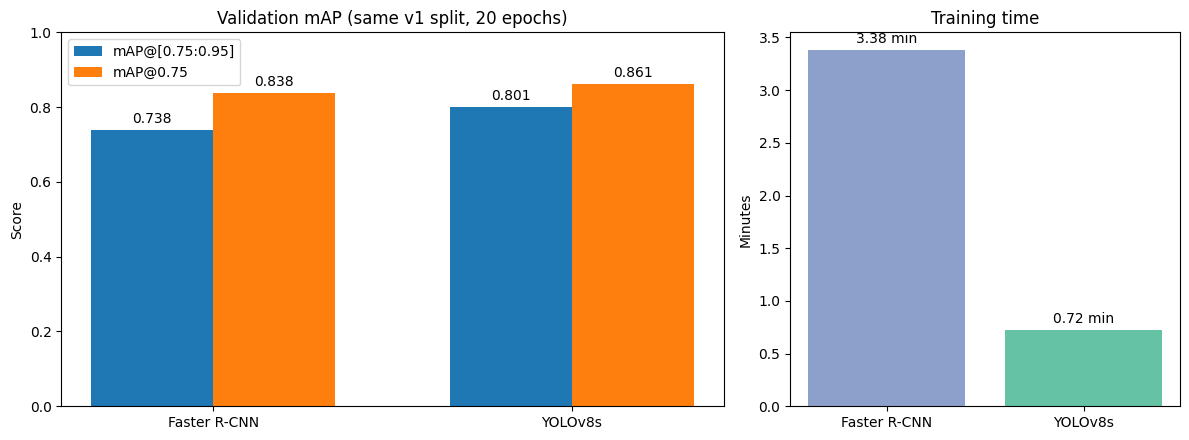

In [37]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Faster R-CNN", "YOLOv8s"]
map_075_095 = [0.73839, 0.80109]
map_75 = [0.83801, 0.86084]
train_minutes = [3.38, 0.72]

x = np.arange(len(models))
width = 0.34

fig, (ax_map, ax_time) = plt.subplots(
    1, 2, figsize=(12, 4.5),
    gridspec_kw={"width_ratios": [1.7, 1]}
)

# mAP 비교
bars1 = ax_map.bar(x - width / 2, map_075_095, width, label="mAP@[0.75:0.95]")
bars2 = ax_map.bar(x + width / 2, map_75, width, label="mAP@0.75")

ax_map.set_title("Validation mAP (same v1 split, 20 epochs)")
ax_map.set_ylabel("Score")
ax_map.set_xticks(x, models)
ax_map.set_ylim(0, 1)
ax_map.legend()
ax_map.bar_label(bars1, fmt="%.3f", padding=3)
ax_map.bar_label(bars2, fmt="%.3f", padding=3)

# 학습 시간 비교
bars_time = ax_time.bar(models, train_minutes, color=["#8da0cb", "#66c2a5"])
ax_time.set_title("Training time")
ax_time.set_ylabel("Minutes")
ax_time.bar_label(bars_time, fmt="%.2f min", padding=3)

plt.tight_layout()
plt.show()

| 비교 항목 | Faster R-CNN | YOLOv8s | YOLO 차이 |
|---|---:|---:|---:|
| mAP@[0.75:0.95] | 0.73839 | 0.80109 | +0.06270, 약 **6.27%p** |
| mAP@0.75 | 0.83801 | 0.86084 | +0.02283, 약 **2.28%p** |
| 학습 시간 | 3.38분 | 0.72분 | 약 **4.7배 빠름** |

같은 v1 데이터 분할에서 각 모델을 20 epoch 학습해 비교한 결과, YOLOv8s의 mAP@[0.75:0.95]와 mAP@0.75가 Faster R-CNN보다 각각 0.06270, 0.02283 높았다. 학습 시간은 YOLOv8s가 0.72분, Faster R-CNN이 3.38분으로 측정되어 이번 실험 조건에서는 YOLOv8s가 성능과 학습 시간 모두 유리했다.

In [38]:
from pathlib import Path
from io import BytesIO
import base64

# 위 그래프 셀에서 만든 fig를 HTML 안에 이미지로 넣기
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=160, bbox_inches="tight")
chart_base64 = base64.b64encode(image_buffer.getvalue()).decode("utf-8")

html = f"""
<!doctype html>
<html lang="ko">
<head>
  <meta charset="utf-8">
  <title>YOLOv8s와 Faster R-CNN 비교</title>
  <style>
    body {{ font-family: Arial, sans-serif; max-width: 1000px; margin: 40px auto; line-height: 1.6; }}
    img {{ width: 100%; height: auto; }}
  </style>
</head>
<body>
  <h1>YOLOv8s와 Faster R-CNN 비교</h1>
  <p>같은 v1 데이터 분할에서 두 모델을 각각 20 epoch 학습해 비교했습니다.</p>
  <img src="data:image/png;base64,{chart_base64}" alt="모델별 mAP 및 학습 시간 비교 그래프">
  <p>이번 실험에서는 YOLOv8s의 두 mAP 점수가 더 높았고, 학습 시간은 더 짧았습니다.
  검증 데이터 47장으로 진행한 한 번의 비교 결과이므로, 이번 데이터 분할과 설정에서의 결과로 해석합니다.</p>
</body>
</html>
"""

output_path = Path("/content/YacssoK/reports/model_comparison_v1_20epochs.html")
output_path.parent.mkdir(parents=True, exist_ok=True)
output_path.write_text(html, encoding="utf-8")

print("저장 완료:", output_path)

저장 완료: /content/YacssoK/reports/model_comparison_v1_20epochs.html
